# AI in Fluids - Week 3 Lab 2

<!-- FLOWMLLAB_COLAB_LAUNCH_V1 -->
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week03/AI_in_Fluids_Week3_Lab2_Mini_DSMC_Cavity_Revised_Student.ipynb)
## From a mini DSMC cavity to an optional validation-quality molecular cavity

This notebook continues the **same lid-driven cavity story** used in Week 1. Week 1 solved a continuum cavity and validated it against Ghia. Here, representative particles move, reflect from walls, collide stochastically inside cells, and are averaged to create noisy macroscopic fields.

### Two-part scope

**Part I - required, CPU:** the dimensionless mini DSMC-style model in Sections 0-10. It is deliberately small enough to run during the lab and is used to learn movement-collision splitting, diffuse walls, stochastic elastic collisions, sampling, noise, and ML-ready metadata.

**Part II - optional bonus, GPU:** the Mohammadzadeh-type argon cavity in Section 11. This extension uses the supplied CuPy VHS-NTC solver, includes a long run that may take roughly **one to two hours** depending on the GPU, and asks for a limited grid/PPC independence check plus validation at $Kn=0.05$.

### Hardware rule

- Run the **required mini cavity on a CPU**.
- Run the **optional production cavity on an NVIDIA GPU** using CuPy.
- A CPU-only/login-node production run is not accepted for the optional extension. The solver's `--debug-cpu` mode is only for tiny development tests, not scientific results.

### Submission reminder

The submission structure does **not** change. Submit only:

1. the completed Lab 1 notebook,
2. this completed Lab 2 notebook, and
3. one Week-3 PDF report containing all final written answers and any optional-extension results.

Do not upload extra folders as separate required deliverables; keep optional plots, tables, and validation output visible in this notebook and summarized in the same PDF report.

## 0. Article-aligned solver validation comes first

<!-- MIE690A article-aligned validation v3 -->

This is a validation of **our executed HS--NTC DSMC solver**, not a pasted literature panel. The target is the hard-sphere argon cavity reported by Mohammadzadeh *et al.* at $Re=1.5$, $Kn=0.1$, and $Ma=0.09$. The observable is $p/p_0$ along A(bottom-left)--B(top-left)--C(top-right)--D(bottom-right)--A.

The black markers below were extracted from the vector paths of the published figure. The blue curve is our retained $60^2$, 50-particles-per-cell run with 6000 field samples. The ochre curve and band are the mean and run-to-run $\pm1\sigma$ spread of three independent $40^2$ runs. The second panel reports pointwise discrepancies so that visually overlapping curves are not mistaken for identical results.


In [1]:
# FLOWMLLAB_COLAB_BOOTSTRAP_V1
# In Colab this cell obtains the complete repository and installs the tested package.
# In a local checkout it leaves the active environment and working directory unchanged.
from pathlib import Path as _FlowMLLabPath
import os as _flowmllab_os
import subprocess as _flowmllab_subprocess
import sys as _flowmllab_sys

if "google.colab" in _flowmllab_sys.modules or _flowmllab_os.environ.get("COLAB_RELEASE_TAG"):
    _flowmllab_root = _FlowMLLabPath("/content/FlowMLLab")
    if not (_flowmllab_root / ".git").is_dir():
        _flowmllab_subprocess.run(
            [
                "git", "clone", "--depth", "1",
                "https://github.com/Ehsan-Roohi/FlowMLLab.git", str(_flowmllab_root),
            ],
            check=True,
        )
    _flowmllab_subprocess.run(
        [
            _flowmllab_sys.executable, "-m", "pip", "install", "-q", "-e",
            f"{_flowmllab_root}[test]",
        ],
        check=True,
    )
    _flowmllab_notebook_dir = _flowmllab_root / "notebooks/week03"
    _flowmllab_os.chdir(_flowmllab_notebook_dir)
    for _flowmllab_path in (_flowmllab_root, _flowmllab_notebook_dir):
        if str(_flowmllab_path) not in _flowmllab_sys.path:
            _flowmllab_sys.path.insert(0, str(_flowmllab_path))
    print("FlowMLLab ready:", _flowmllab_root)

from pathlib import Path
import sys

def locate_course_root(start=Path.cwd()):
    for origin in (Path(start).resolve(), Path.cwd().resolve()):
        for candidate in (origin, *origin.parents):
            if (candidate / "common" / "article_validation.py").exists():
                return candidate
    raise FileNotFoundError(
        "Run this notebook inside the complete MIE690A release; common/article_validation.py is required."
    )

COURSE_ROOT = locate_course_root()
sys.path.insert(0, str(COURSE_ROOT / "common"))
from article_validation import (
    build_dsmc_wall_pressure_validation,
    build_ghia_velocity_validation,
    build_pressure_validation,
)
print("Course root:", COURSE_ROOT)


Course root: D:\ChatGPT Backup\Projects\FlowMLLab\Teaching_Current\repo


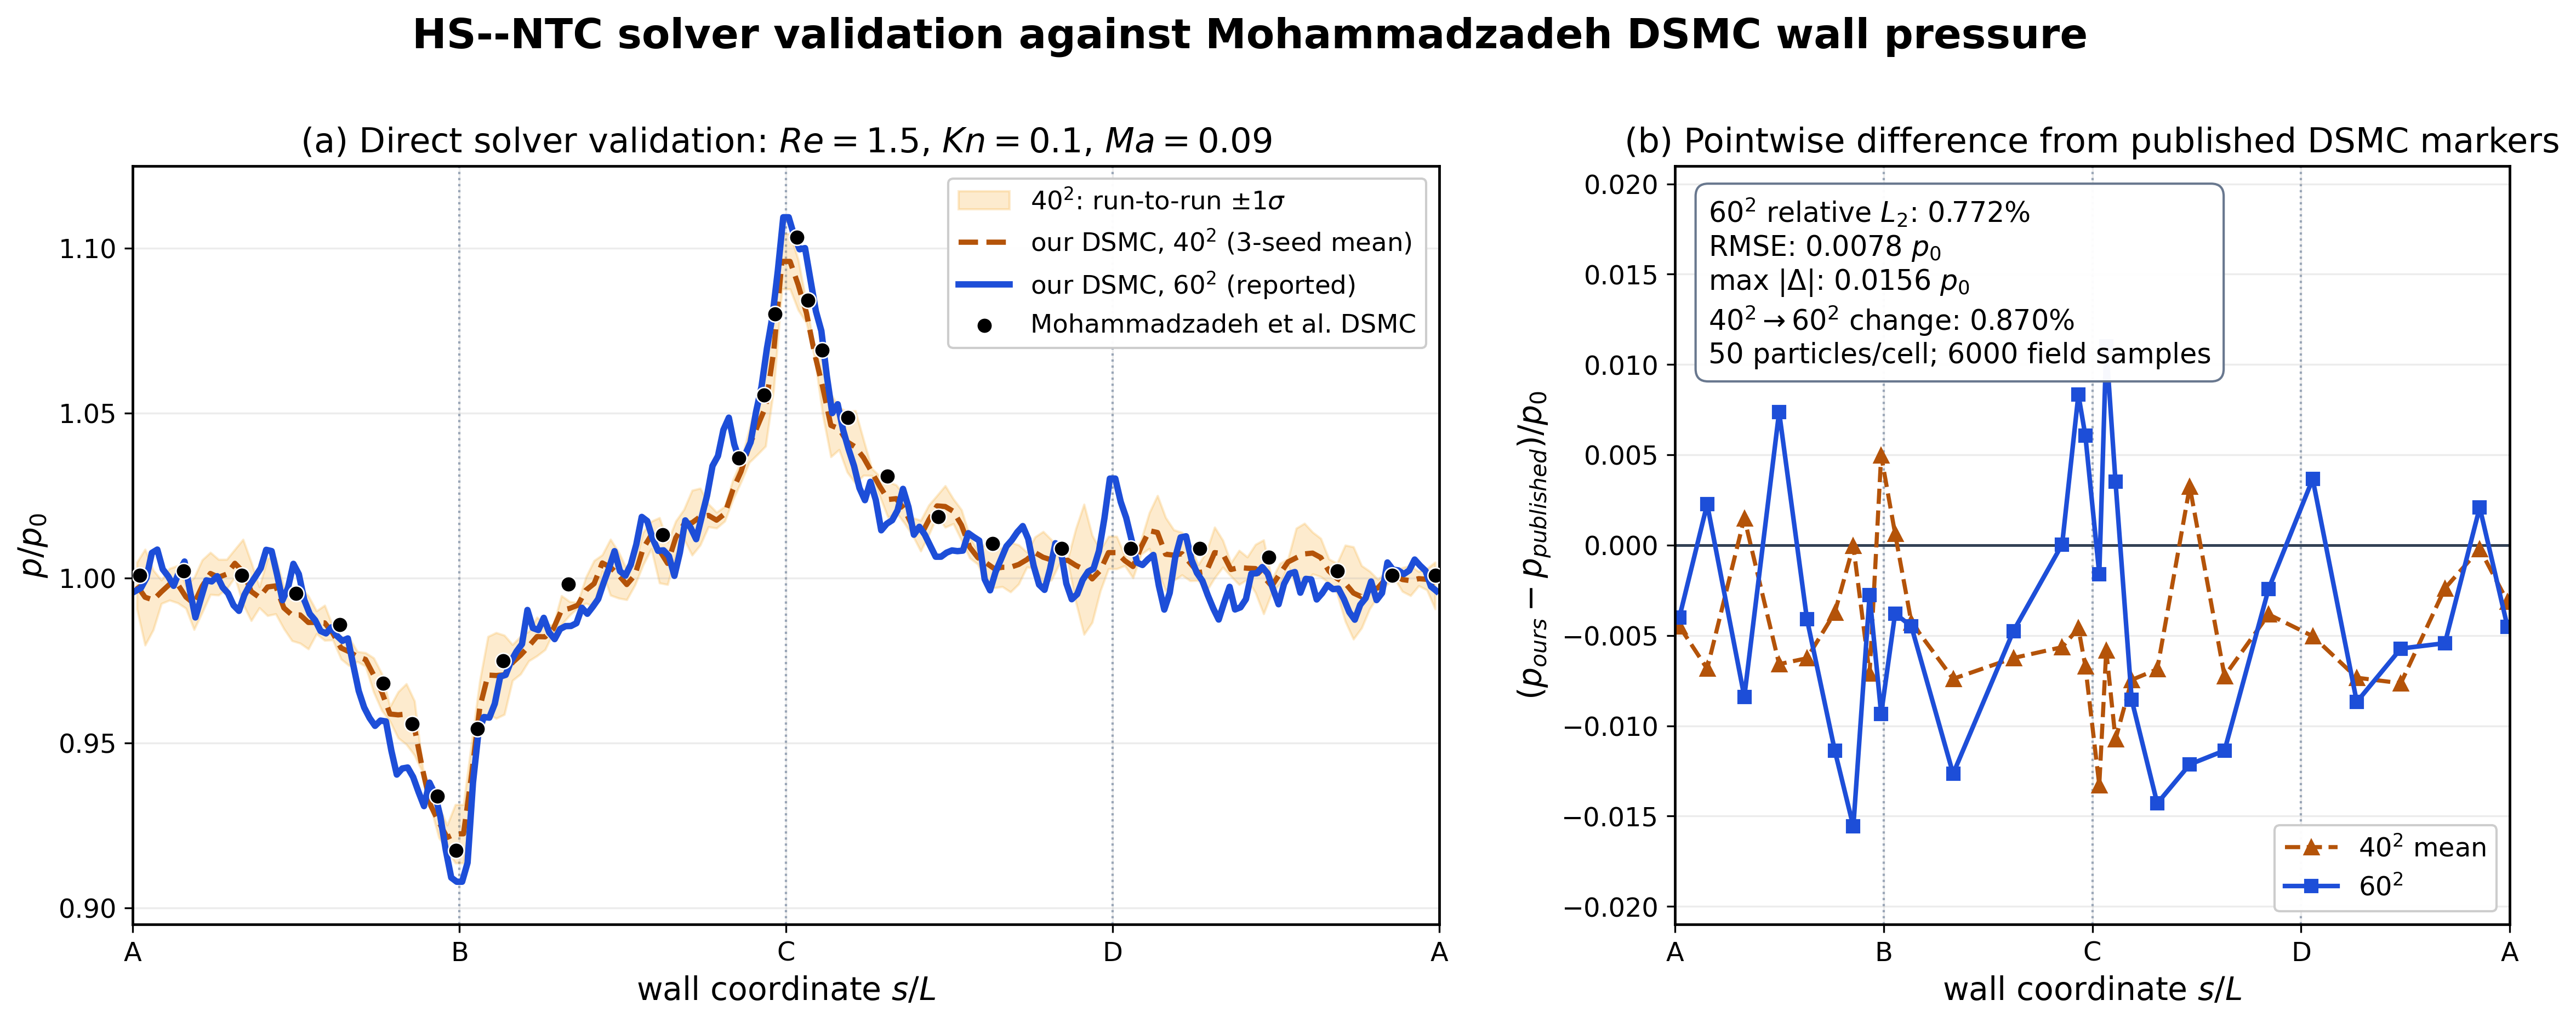

,relative_l2,rmse_over_p0,max_abs_over_p0,grid_change_40_to_60,fine_run,coarse_runs
0,0.007723,0.007801,0.015575,0.008696,ref_n60_seed07,"[ref_n40_seed07, ref_n40_seed19, ref_n40_seed31]"


Paper-ready file: D:\ChatGPT Backup\Projects\FlowMLLab\Teaching_Current\repo\student_runs\article_validation\fig10a_mohammadzadeh_validation.pdf


In [2]:
from IPython.display import Image, display
import pandas as pd

STUDENT_OUTPUT = COURSE_ROOT / 'student_runs/article_validation'
dsmc_validation = build_dsmc_wall_pressure_validation(COURSE_ROOT, STUDENT_OUTPUT)
display(Image(filename=str(dsmc_validation["figure"]["png"]), width=1150))
display(pd.DataFrame([dsmc_validation["metrics"]]))
print("Paper-ready file:", dsmc_validation["figure"]["pdf"])


In [3]:
# Optional full recomputation with the same solver kernel and declared budgets.
# The retained outputs above are genuine completed runs. Turn this on only when you
# want to regenerate all four realizations (CPU time depends strongly on hardware).
RUN_FULL_DSMC_VALIDATION = False

if RUN_FULL_DSMC_VALIDATION:
    import subprocess
    runner = COURSE_ROOT / "notebooks" / "week03" / "run_wall_pressure_case.py"
    output = COURSE_ROOT / "results" / "dsmc_validation" / "runs"
    specifications = [
        (40, 7, 12000, 4000, 0.05, "ref_n40_seed07"),
        (40, 19, 12000, 4000, 0.05, "ref_n40_seed19"),
        (40, 31, 12000, 4000, 0.05, "ref_n40_seed31"),
        (60, 7, 18000, 6000, 0.04, "ref_n60_seed07"),
    ]
    for grid, seed, steps, sample_start, dt_factor, case_name in specifications:
        command = [
            sys.executable, str(runner), "--grid", str(grid), "--ppc", "50",
            "--steps", str(steps), "--sample-start", str(sample_start),
            "--sample-stride", "2", "--dt-factor", str(dt_factor),
            "--seed", str(seed), "--output-dir", str(output), "--case-name", case_name,
        ]
        print("$", " ".join(command))
        subprocess.run(command, cwd=runner.parent, check=True)
    dsmc_validation = build_dsmc_wall_pressure_validation(COURSE_ROOT, STUDENT_OUTPUT)
    display(Image(filename=str(dsmc_validation["figure"]["png"]), width=1150))
else:
    print("Using four retained completed runs; set the switch to rerun the production validation.")


Using four retained completed runs; set the switch to rerun the production validation.


## 0. Imports

In [4]:
from dataclasses import dataclass, asdict
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

np.set_printoptions(precision=5, suppress=True)

## 1. DSMC-style flowchart

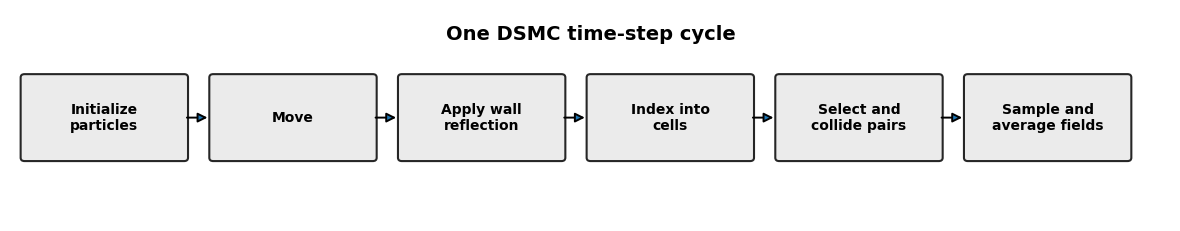

In [5]:
labels = [
    "Initialize\nparticles",
    "Move",
    "Apply wall\nreflection",
    "Index into\ncells",
    "Select and\ncollide pairs",
    "Sample and\naverage fields",
]

fig, ax = plt.subplots(figsize=(12, 2.5))
ax.set_xlim(0, 12)
ax.set_ylim(0, 2.5)
ax.axis("off")
for i, label in enumerate(labels):
    x = 0.15 + 1.95*i
    box = FancyBboxPatch((x, 0.75), 1.65, 0.95, boxstyle="round,pad=0.04",
                         linewidth=1.5, edgecolor="0.15", facecolor="0.92")
    ax.add_patch(box)
    ax.text(x+0.825, 1.225, label, ha="center", va="center", fontsize=10, weight="bold")
    if i < len(labels)-1:
        ax.add_patch(FancyArrowPatch((x+1.65, 1.225), (x+1.92, 1.225),
                                     arrowstyle="-|>", mutation_scale=14, linewidth=1.4))
ax.text(6.0, 2.15, "One DSMC time-step cycle", ha="center", fontsize=14, weight="bold")
plt.tight_layout()
plt.show()

### Report prompt 1
Include this flowchart in the report. Explain each block, identify where randomness enters, and state where pair momentum and kinetic energy are conserved.

> **Your response:** Write a concise answer here for your own record, and include the final version in the PDF report.
>
> ...

## 2. Configuration and model assumptions

### Trace each control to a physical or statistical question

The square has $L=1$ and molecular component variance $T_{wall}$; thus $\bar c=\sqrt{8T_{wall}/\pi}$ and the model collision time is $\tau\approx Kn/\bar c$. `Kn` sets a teaching collision rate, not a calibrated hard-sphere cross section. The comparison with the retained dimensional HS-NTC solver above is contextual; do not score this mini solver against that different physical case.

`nx,ny` define collision/sampling cells; `ppc` defines initial particles per cell, with total $N_p=n_xn_y\,ppc$. `dt` advances molecular positions, `steps` fixes final physical time, `sample_start` discards startup, and `sample_stride` selects stored field observations. Adjacent observations can remain correlated. `seed` selects one realization. `Uwall` controls tangential drift in diffuse lid emission, and `T_wall` controls thermal velocities at every wall.

The supplied quick and better-sampled configurations change grid, particles, time step, averaging window **and seed**. Their difference is not an isolated grid-convergence or sampling-error estimate. Use them to diagnose what metadata are needed; the controlled experiments at the end change one factor and compare identical physical averaging windows.


In [6]:
@dataclass
class MiniDSMCConfig:
    Kn: float = 0.1
    nx: int = 16
    ny: int = 16
    ppc: int = 8
    steps: int = 650
    sample_start: int = 300
    sample_stride: int = 10
    dt: float = 0.003
    Uwall: float = 0.6
    T_wall: float = 1.0
    seed: int = 2
    label: str = "quick"

    @property
    def n_particles(self):
        return self.nx*self.ny*self.ppc

    @property
    def mean_thermal_speed(self):
        # Dimensionless mean speed for a 3-D Maxwellian with component variance T=1.
        return np.sqrt(8.0*self.T_wall/np.pi)

    @property
    def approximate_mean_collision_time(self):
        # In this teaching scaling, mean free path = Kn*L and L=1.
        return self.Kn/self.mean_thermal_speed


quick_cfg = MiniDSMCConfig()
better_cfg = MiniDSMCConfig(nx=20, ny=20, ppc=24, steps=2200,
                            sample_start=700, sample_stride=3, dt=0.0025,
                            seed=4, label="better sampled")

pd.DataFrame([asdict(quick_cfg), asdict(better_cfg)])

,Kn,nx,ny,ppc,steps,sample_start,sample_stride,dt,Uwall,T_wall,seed,label
0,0.1,16,16,8,650,300,10,0.0030,0.6,1.0,2,quick
1,0.1,20,20,24,2200,700,3,0.0025,0.6,1.0,4,better sampled


The model uses three molecular-velocity components but two spatial coordinates. All walls are diffuse and isothermal. The top wall has a tangential velocity. Collision frequency is scaled approximately as the inverse of Knudsen number. The collision model is intentionally simplified; the later project uses VHS and NTC.

## 3. Particle movement and diffuse wall reflection

In [7]:
def apply_diffuse_walls(position, velocity, cfg, rng):
    """Reflect particles diffusely from stationary walls and the moving top lid."""
    T = cfg.T_wall
    sigma = np.sqrt(T)

    left = position[:, 0] < 0.0
    if np.any(left):
        position[left, 0] *= -1.0
        n = int(left.sum())
        velocity[left, 0] = np.sqrt(-2*T*np.log(np.maximum(rng.random(n), 1e-15)))
        velocity[left, 1] = sigma*rng.standard_normal(n)
        velocity[left, 2] = sigma*rng.standard_normal(n)

    right = position[:, 0] > 1.0
    if np.any(right):
        position[right, 0] = 2.0 - position[right, 0]
        n = int(right.sum())
        velocity[right, 0] = -np.sqrt(-2*T*np.log(np.maximum(rng.random(n), 1e-15)))
        velocity[right, 1] = sigma*rng.standard_normal(n)
        velocity[right, 2] = sigma*rng.standard_normal(n)

    bottom = position[:, 1] < 0.0
    if np.any(bottom):
        position[bottom, 1] *= -1.0
        n = int(bottom.sum())
        velocity[bottom, 0] = sigma*rng.standard_normal(n)
        velocity[bottom, 1] = np.sqrt(-2*T*np.log(np.maximum(rng.random(n), 1e-15)))
        velocity[bottom, 2] = sigma*rng.standard_normal(n)

    top = position[:, 1] > 1.0
    if np.any(top):
        position[top, 1] = 2.0 - position[top, 1]
        n = int(top.sum())
        velocity[top, 0] = cfg.Uwall + sigma*rng.standard_normal(n)
        velocity[top, 1] = -np.sqrt(-2*T*np.log(np.maximum(rng.random(n), 1e-15)))
        velocity[top, 2] = sigma*rng.standard_normal(n)

## 4. Cell-based stochastic elastic collisions

For an identical-particle pair define $\mathbf V=(\mathbf v_1+\mathbf v_2)/2$ and $g=|\mathbf v_1-\mathbf v_2|$. The code draws a unit direction $\mathbf e$ uniformly on the sphere and returns $\mathbf v'_1=\mathbf V+g\mathbf e/2$ and $\mathbf v'_2=\mathbf V-g\mathbf e/2$. Therefore pair momentum and kinetic energy are conserved independently of the random direction. Isotropy requires uniform $\cos\theta$, not uniform polar angle.

Within each cell the expected number of pairs is approximately $N_{cell}\bar c\Delta t/(2KnL)$. Stochastic rounding gives an integer count without systematically truncating rare collisions. This simplified rate ignores pair-speed-dependent acceptance and is **not the VHS-NTC algorithm** used in the optional production solver. Conservation is necessary but cannot by itself validate collision statistics.


In [8]:
def collide_one_pair(v1, v2, rng):
    """Isotropic elastic collision for identical monatomic particles."""
    v_cm = 0.5*(v1 + v2)
    g = np.linalg.norm(v1 - v2)
    mu = 2.0*rng.random() - 1.0
    phi = 2.0*np.pi*rng.random()
    sin_theta = np.sqrt(max(0.0, 1.0 - mu*mu))
    direction = np.array([sin_theta*np.cos(phi), sin_theta*np.sin(phi), mu])
    return v_cm + 0.5*g*direction, v_cm - 0.5*g*direction


def collide_in_cells(position, velocity, cfg, rng):
    """Teaching collision step: random local pairs with a Kn-scaled rate."""
    ix = np.minimum((position[:, 0]*cfg.nx).astype(np.int64), cfg.nx-1)
    iy = np.minimum((position[:, 1]*cfg.ny).astype(np.int64), cfg.ny-1)
    cell_id = ix + cfg.nx*iy
    order = np.argsort(cell_id)
    sorted_id = cell_id[order]
    _, starts, counts = np.unique(sorted_id, return_index=True, return_counts=True)

    # Approximate expected collisions per particle during dt: c_bar*dt/(Kn*L), L=1.
    for start, count in zip(starts, counts):
        if count < 2:
            continue
        expected_pairs = 0.5*count*cfg.mean_thermal_speed*cfg.dt/max(cfg.Kn, 1e-12)
        n_pairs = int(expected_pairs + rng.random())  # stochastic rounding
        if n_pairs == 0:
            continue
        ids = order[start:start+count]
        a = rng.integers(0, count, size=n_pairs)
        b = rng.integers(0, count, size=n_pairs)
        same = a == b
        b[same] = (b[same] + 1) % count
        for i_local, j_local in zip(a, b):
            i, j = ids[i_local], ids[j_local]
            velocity[i], velocity[j] = collide_one_pair(velocity[i], velocity[j], rng)

In [9]:
# Verify pair conservation numerically.
test_rng = np.random.default_rng(10)
v1 = test_rng.standard_normal(3)
v2 = test_rng.standard_normal(3)
p_before = v1 + v2
e_before = np.dot(v1, v1) + np.dot(v2, v2)
v1_new, v2_new = collide_one_pair(v1, v2, test_rng)
p_after = v1_new + v2_new
e_after = np.dot(v1_new, v1_new) + np.dot(v2_new, v2_new)
print("Momentum difference:", p_after - p_before)
print("Kinetic-energy proxy difference:", e_after - e_before)
np.testing.assert_allclose(p_after, p_before, atol=1e-14)
np.testing.assert_allclose(e_after, e_before, atol=1e-14)


Momentum difference: [0. 0. 0.]
Kinetic-energy proxy difference: 4.440892098500626e-16


## 5. Sampling macroscopic fields

## Estimator audit before interpreting the retained temperature maps
The original CPU mini demonstration below is retained as a **biased-estimator
control**, not a quantitative temperature benchmark. Its instantaneous centered
variance uses N rather than N−1; then it averages snapshot temperatures equally.
For fixed iid N the expected factor is (N−1)/N: .875 at N=8 and .95833 at N=24.
Actual cavity populations fluctuate and samples correlate, so these are not
measured bias percentages for these runs. Empty cells have no measured gas
velocity/temperature; the historical positive floor is a numerical placeholder.
Do not interpret it as cold gas. The overlay code below masks empty cells.

P5 uses pooled raw moments and a Bessel correction over a later stationary
window; it preserves counts and avoids averaging biased instantaneous T.
Pooling still assumes a sufficiently stationary mean and does not remove
transient, grid, time-step or collision-model bias. When comparing PPC and time
window together, do not describe the result as changing only noise.

**Required check:** derive E[sum|v−vbar|²]=3(N−1)kBT/m. State which assumptions
fail in a time-correlated transient cavity. Keep historical and revised estimators
in separately labelled tables; never silently regenerate retained maps.

In [10]:
def instantaneous_fields(position, velocity, cfg):
    ix = np.minimum((position[:, 0]*cfg.nx).astype(np.int64), cfg.nx-1)
    iy = np.minimum((position[:, 1]*cfg.ny).astype(np.int64), cfg.ny-1)
    cell_id = ix + cfg.nx*iy
    n_cells = cfg.nx*cfg.ny

    count = np.bincount(cell_id, minlength=n_cells).astype(float)
    safe = np.maximum(count, 1.0)
    sx = np.bincount(cell_id, weights=velocity[:, 0], minlength=n_cells)
    sy = np.bincount(cell_id, weights=velocity[:, 1], minlength=n_cells)
    sz = np.bincount(cell_id, weights=velocity[:, 2], minlength=n_cells)
    s2 = np.bincount(cell_id, weights=np.sum(velocity**2, axis=1), minlength=n_cells)

    u = sx/safe
    v = sy/safe
    w = sz/safe
    T = np.maximum((s2/safe - (u*u + v*v + w*w))/3.0, 1e-12)
    return count.reshape(cfg.ny, cfg.nx), u.reshape(cfg.ny, cfg.nx), v.reshape(cfg.ny, cfg.nx), T.reshape(cfg.ny, cfg.nx)


def run_mini_dsmc(cfg, progress=True):
    rng = np.random.default_rng(cfg.seed)
    position = rng.random((cfg.n_particles, 2))
    velocity = np.sqrt(cfg.T_wall)*rng.standard_normal((cfg.n_particles, 3))
    velocity -= velocity.mean(axis=0)

    accum = [np.zeros((cfg.ny, cfg.nx)) for _ in range(4)]
    n_field_samples = 0
    start_time = time.time()

    for step in range(cfg.steps):
        position += velocity[:, :2]*cfg.dt
        apply_diffuse_walls(position, velocity, cfg, rng)
        collide_in_cells(position, velocity, cfg, rng)

        if step >= cfg.sample_start and (step-cfg.sample_start) % cfg.sample_stride == 0:
            values = instantaneous_fields(position, velocity, cfg)
            for a, value in zip(accum, values):
                a += value
            n_field_samples += 1

        if progress and (step+1) % max(1, cfg.steps//4) == 0:
            print(f"{cfg.label}: step {step+1}/{cfg.steps}, field samples={n_field_samples}")

    fields = [a/max(n_field_samples, 1) for a in accum]
    runtime = time.time() - start_time
    return {
        "config": cfg,
        "position": position,
        "velocity": velocity,
        "count": fields[0],
        "u": fields[1],
        "v": fields[2],
        "T": fields[3],
        "n_field_samples": n_field_samples,
        "runtime_s": runtime,
    }

In [11]:
# Inspection-only mask: never interpret an unoccupied cell's floor as a gas temperature.
def masked_instantaneous_fields(position, velocity, cfg):
    count, u, v, temperature = instantaneous_fields(position, velocity, cfg)
    return count, np.ma.masked_where(count == 0, u), np.ma.masked_where(count == 0, v), np.ma.masked_where(count < 2, temperature)
# Use this adapter for a single snapshot. Pooled production labels are taught in P5.

## 6. Run the quick and better-sampled cases

In [12]:
quick = run_mini_dsmc(quick_cfg)
print(f"Quick runtime: {quick['runtime_s']:.2f} s")

better = run_mini_dsmc(better_cfg)
print(f"Better-sampled runtime: {better['runtime_s']:.2f} s")

run_table = pd.DataFrame([
    {**asdict(quick_cfg), "particles": quick_cfg.n_particles,
     "field_samples": quick["n_field_samples"], "runtime_s": quick["runtime_s"]},
    {**asdict(better_cfg), "particles": better_cfg.n_particles,
     "field_samples": better["n_field_samples"], "runtime_s": better["runtime_s"]},
])
display(run_table)

quick: step 162/650, field samples=0


quick: step 324/650, field samples=3


quick: step 486/650, field samples=19


quick: step 648/650, field samples=35
Quick runtime: 31.76 s


better sampled: step 550/2200, field samples=0


better sampled: step 1100/2200, field samples=134


better sampled: step 1650/2200, field samples=317


better sampled: step 2200/2200, field samples=500
Better-sampled runtime: 424.79 s


,Kn,nx,ny,ppc,steps,sample_start,sample_stride,dt,Uwall,T_wall,seed,label,particles,field_samples,runtime_s
0,0.1,16,16,8,650,300,10,0.0030,0.6,1.0,2,quick,2048,35,31.760358
1,0.1,20,20,24,2200,700,3,0.0025,0.6,1.0,4,better sampled,9600,500,424.791088


In [13]:
# Sampling occurs after each move: the first recorded time is (sample_start+1)*dt.
window_rows = []
for cfg in (quick_cfg, better_cfg):
    sampled_steps = np.arange(cfg.sample_start, cfg.steps, cfg.sample_stride)
    assert len(sampled_steps) > 0
    window_rows.append({"case":cfg.label,"first_sample_time":(sampled_steps[0]+1)*cfg.dt,
        "last_sample_time":(sampled_steps[-1]+1)*cfg.dt,
        "sample_spacing":cfg.sample_stride*cfg.dt,"recorded_samples":len(sampled_steps),
        "final_time":cfg.steps*cfg.dt,"Uwall/mean_thermal_speed":cfg.Uwall/cfg.mean_thermal_speed})
display(pd.DataFrame(window_rows))


,case,first_sample_time,last_sample_time,sample_spacing,recorded_samples,final_time,Uwall/mean_thermal_speed
0,quick,0.9030,1.923,0.0300,35,1.95,0.375994
1,better sampled,1.7525,5.495,0.0075,500,5.50,0.375994


## 7. Particle snapshot and averaged fields

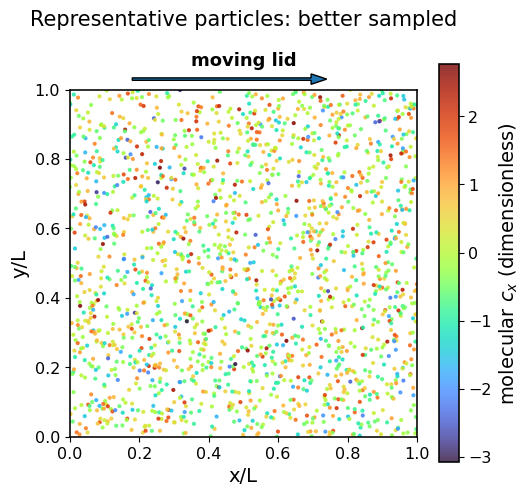

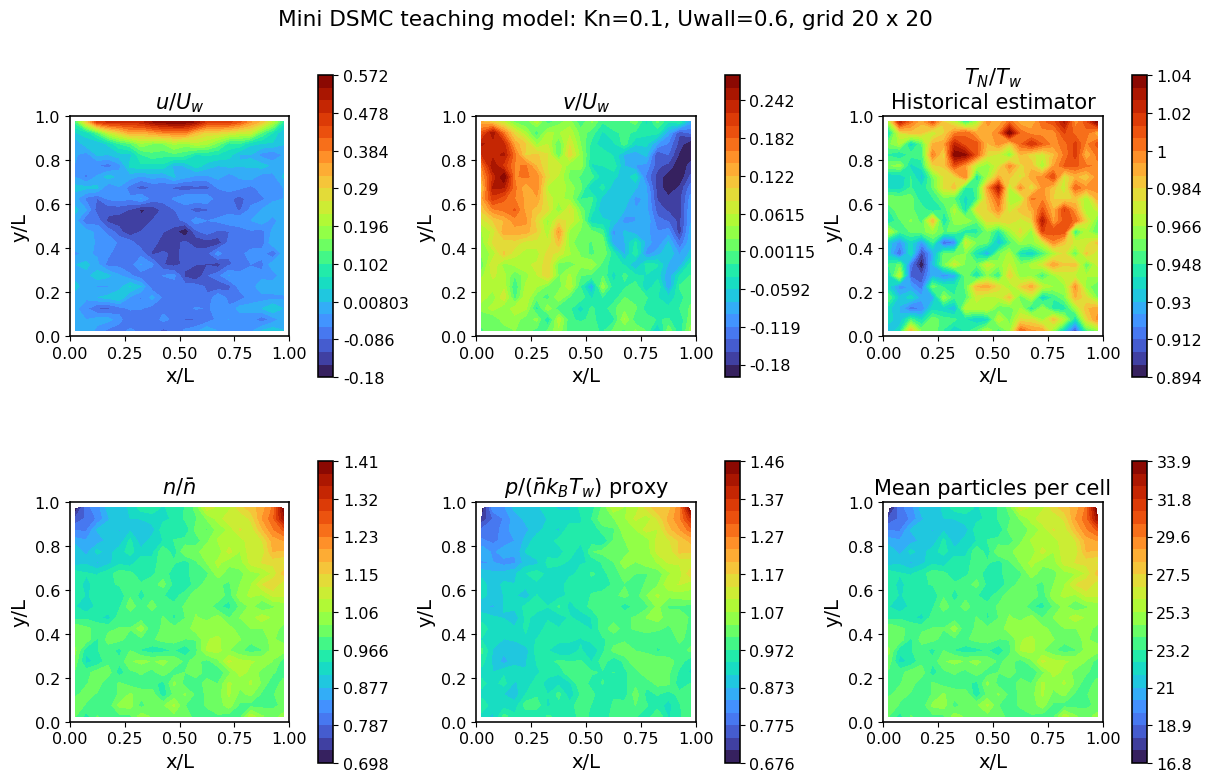

In [14]:
def plot_particle_snapshot(case, max_particles=1800):
    cfg = case["config"]
    n = len(case["position"])
    ids = np.linspace(0, n-1, min(n, max_particles), dtype=int)

    fig, ax = plt.subplots(figsize=(5.6, 5.6))
    scatter = ax.scatter(case["position"][ids, 0], case["position"][ids, 1],
                         c=case["velocity"][ids, 0], s=4, cmap="turbo",
                         vmin=float(case["velocity"][ids,0].min()),
                         vmax=float(case["velocity"][ids,0].max()), alpha=0.8)

    # Keep the moving-lid annotation below the title so the two never overlap.
    ax.set_title(f"Representative particles: {cfg.label}", pad=46)
    ax.arrow(0.18, 1.030, 0.56, 0.0, width=0.007, head_width=0.030,
             head_length=0.045, length_includes_head=True, clip_on=False)
    ax.text(0.50, 1.058, "moving lid", ha="center", va="bottom", weight="bold")
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="x/L", ylabel="y/L", aspect="equal")
    plt.colorbar(scatter, ax=ax, label=r"molecular $c_x$ (dimensionless)")
    fig.subplots_adjust(top=0.82)
    plt.show()


def plot_fields(case):
    """Native unsmoothed means; preserve extrema and identify the biased teaching estimator."""
    cfg = case["config"]
    x=(np.arange(cfg.nx)+.5)/cfg.nx; y=(np.arange(cfg.ny)+.5)/cfg.ny
    rho=case["count"]/case["count"].mean()
    fields=[case["u"]/cfg.Uwall, case["v"]/cfg.Uwall, case["T"]/cfg.T_wall,
            rho, rho*case["T"]/cfg.T_wall, case["count"]]
    labels=[r"$u/U_w$",r"$v/U_w$",r"$T_N/T_w$"+"\nHistorical estimator",
            r"$n/\bar n$",r"$p/(\bar n k_BT_w)$ proxy", "Mean particles per cell"]
    fig,axes=plt.subplots(2,3,figsize=(12,8),layout="constrained")
    for ax,field,label in zip(axes.flat,fields,labels):
        lo,hi=float(field.min()),float(field.max())
        if lo==hi: hi=lo+1e-12
        im=ax.contourf(x,y,field,levels=np.linspace(lo,hi,25),cmap="turbo")
        fig.colorbar(im,ax=ax,shrink=.8,format="%.3g")
        ax.set(xlabel="x/L",ylabel="y/L",title=label,aspect="equal",xlim=(0,1),ylim=(0,1))
    fig.suptitle(f"Mini DSMC teaching model: Kn={cfg.Kn}, Uwall={cfg.Uwall}, grid {cfg.nx} x {cfg.ny}")
    plt.show()


plot_particle_snapshot(better)
plot_fields(better)
# Quick fields remain in memory; compare their raw profiles below, not noisy contour topology.


### Report prompt 2
Identify evidence of tangential momentum transfer from the moving lid and evidence of recirculation. Which features are robust, and which remain visibly noisy?

> **Your response:** Write a concise answer here for your own record, and include the final version in the PDF report.
>
> ...

## 8. Quantitative comparison of the two runs

Relative L2 difference between quick and better u-fields: 0.728


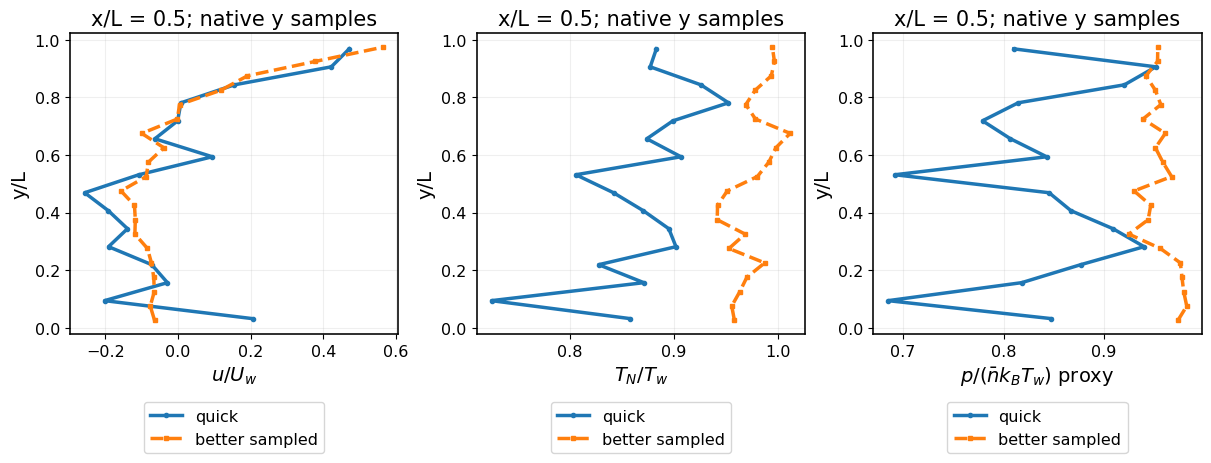

These are unmatched-window realizations; their difference is not a confidence interval.


In [15]:
def resample_field(field, new_nx, new_ny):
    old_ny, old_nx = field.shape
    x_old = (np.arange(old_nx)+0.5)/old_nx
    y_old = (np.arange(old_ny)+0.5)/old_ny
    x_new = (np.arange(new_nx)+0.5)/new_nx
    y_new = (np.arange(new_ny)+0.5)/new_ny
    temp = np.vstack([np.interp(x_new, x_old, row) for row in field])
    out = np.vstack([np.interp(y_new, y_old, temp[:, i]) for i in range(new_nx)]).T
    return out


u_quick_on_better = resample_field(quick["u"]/quick_cfg.Uwall, better_cfg.nx, better_cfg.ny)
u_better = better["u"]/better_cfg.Uwall
relative_l2_difference = np.linalg.norm(u_quick_on_better-u_better)/(np.linalg.norm(u_better)+1e-14)
print(f"Relative L2 difference between quick and better u-fields: {relative_l2_difference:.3f}")

# Average the two straddling cell centers at x/L=0.5; no wall extrapolation.
fig,axes=plt.subplots(1,3,figsize=(12,4.5),layout="constrained")
for case,style in ((quick,"o-"),(better,"s--")):
    cfg=case["config"];x=(np.arange(cfg.nx)+.5)/cfg.nx;y=(np.arange(cfg.ny)+.5)/cfg.ny
    rho=case["count"]/case["count"].mean()
    quantities=[case["u"]/cfg.Uwall,case["T"]/cfg.T_wall,rho*case["T"]/cfg.T_wall]
    for ax,field in zip(axes,quantities):
        profile=np.array([np.interp(.5,x,row) for row in field])
        ax.plot(profile,y,style,ms=3,label=cfg.label)
for ax,label in zip(axes,[r"$u/U_w$",r"$T_N/T_w$",r"$p/(\bar n k_BT_w)$ proxy"]):
    ax.set(xlabel=label,ylabel="y/L",title="x/L = 0.5; native y samples")
    ax.grid(alpha=.2);ax.legend(loc="upper center",bbox_to_anchor=(.5,-.2))
plt.show()
print("These are unmatched-window realizations; their difference is not a confidence interval.")


### Report prompt 3
Report the relative L2 field difference. Explain why more particles and a longer average reduce random roughness but do not establish grid or time-step independence.

> **Your response:** Write a concise answer here for your own record, and include the final version in the PDF report.
>
> ...

## 9. DSMC quality indicators

In [16]:
def quality_table(cfg):
    dx = 1.0/cfg.nx
    dy = 1.0/cfg.ny
    mean_free_path = cfg.Kn
    tau_collision = cfg.approximate_mean_collision_time
    return {
        "case": cfg.label,
        "dx/lambda": dx/mean_free_path,
        "dy/lambda": dy/mean_free_path,
        "dt/tau_collision": cfg.dt/tau_collision,
        "particles_per_cell": cfg.ppc,
    }

quality_df = pd.DataFrame([quality_table(quick_cfg), quality_table(better_cfg)])
display(quality_df)

,case,dx/lambda,dy/lambda,dt/tau_collision,particles_per_cell
0,quick,0.625,0.625,0.047873,8
1,better sampled,0.500,0.500,0.039894,24


### Report prompt 4
Interpret the cell-size and time-step ratios. State why the usual DSMC guidance is to resolve the mean free path, collision time, and important gradients.

> **Your response:** Write a concise answer here for your own record, and include the final version in the PDF report.
>
> ...

## 10. Export a machine-learning table

In [17]:
def case_to_dataframe(case):
    cfg = case["config"]
    x = (np.arange(cfg.nx)+0.5)/cfg.nx
    y = (np.arange(cfg.ny)+0.5)/cfg.ny
    X, Y = np.meshgrid(x, y)
    rho_star = case["count"]/np.mean(case["count"])
    return pd.DataFrame({
        "log10_Kn": np.log10(cfg.Kn),
        "Kn": cfg.Kn,
        "Uwall_over_cth": cfg.Uwall/cfg.mean_thermal_speed,
        "x_over_L": X.ravel(),
        "y_over_L": Y.ravel(),
        "rho_over_mean": rho_star.ravel(),
        "u_over_Uwall": (case["u"]/cfg.Uwall).ravel(),
        "v_over_Uwall": (case["v"]/cfg.Uwall).ravel(),
        "T_over_T0": (case["T"]/cfg.T_wall).ravel(),
        "nx": cfg.nx,
        "ny": cfg.ny,
        "ppc": cfg.ppc,
        "field_samples": case["n_field_samples"],
        "seed": cfg.seed,
        "source_model": "mini_teaching_DSMC",
    })

cavity_dataset = case_to_dataframe(better)
display(cavity_dataset.head())
cavity_dataset.to_csv("week3_mini_cavity_dataset.csv", index=False)
print("Saved week3_mini_cavity_dataset.csv with", len(cavity_dataset), "rows")

,log10_Kn,Kn,Uwall_over_cth,x_over_L,y_over_L,rho_over_mean,u_over_Uwall,v_over_Uwall,T_over_T0,nx,ny,ppc,field_samples,seed,source_model
0,-1.0,0.1,0.375994,0.025,0.025,0.997167,0.007484,-0.000118,0.930113,20,20,24,500,4,mini_teaching_DSMC
1,-1.0,0.1,0.375994,0.075,0.025,0.953583,0.001104,0.006812,0.940705,20,20,24,500,4,mini_teaching_DSMC
2,-1.0,0.1,0.375994,0.125,0.025,0.997167,-0.033217,0.007349,0.986729,20,20,24,500,4,mini_teaching_DSMC
3,-1.0,0.1,0.375994,0.175,0.025,0.990250,-0.063203,0.021483,0.957624,20,20,24,500,4,mini_teaching_DSMC
4,-1.0,0.1,0.375994,0.225,0.025,0.987000,-0.073478,0.011160,0.959054,20,20,24,500,4,mini_teaching_DSMC


Saved week3_mini_cavity_dataset.csv with 400 rows


### Report prompt 5
List the proposed ML features, targets, and data-quality metadata. Explain why a safe train/test split should hold out entire simulation cases or Knudsen numbers rather than randomly splitting grid points from the same field.

> **Your response:** Write a concise answer here for your own record, and include the final version in the PDF report.
>
> ...

## 11. Optional bonus extension - a validation-quality GPU molecular cavity

This section turns the short teaching model into a small scientific workflow. It is **optional** and can earn up to the bonus stated in the assignment. It is intentionally more demanding than the required CPU exercise.

### Physical case

Use the supplied `dsmc_cavity_vhs_ntc_gpu_week3.py` solver for an isothermal argon lid-driven cavity with:

- $Kn=0.05$,
- $L=1.0\times10^{-6}\ \mathrm{m}$,
- $T_0=T_{wall}=300\ \mathrm{K}$,
- $U_{wall}=100\ \mathrm{m/s}$,
- a VHS molecular model, NTC-style collision selection, and fully diffuse walls.

The goal is not to run as many cases as Project 1. For Week 3, use **one Knudsen number** to learn four ideas well:

1. a smoke test is not a final result;
2. longer particle-time averaging improves a stochastic field;
3. grid and particle-number dependence must be checked before claiming a good solution;
4. a molecular result should be compared with published data, not judged only by a smooth contour.

### What remains for Project 1

The three-$Kn$ validation campaign, time-step independence, full sampling-window independence, the multi-$Kn$ AI dataset, and the vortex-center trend with $Kn$ remain Project-1 work. Do not expand Week 3 into the complete project.

In [18]:
from pathlib import Path
import json
import os
import subprocess
import sys

GPU_SOLVER = Path("dsmc_cavity_vhs_ntc_gpu_week3.py")
GPU_BATCH = Path("run_week3_gpu_cavity_study.py")
GPU_OUTPUT_ROOT = Path("week3_gpu_output")

# All flags are False so the notebook remains safe to execute on a CPU.
# Change one flag at a time only after the GPU preflight check succeeds.
RUN_GPU_PREFLIGHT = False
RUN_GPU_SMOKE = False
RUN_GPU_GRID = False
RUN_GPU_PPC = False
RUN_GPU_FINAL = False

run_plan = pd.DataFrame([
    {"stage": "smoke", "case": "smoke_40_ppc8", "nx": 40, "ny": 40, "PPC": 8,
     "steps": 500, "sample_start": 250, "sample_stride": 5, "purpose": "installation/debug only"},
    {"stage": "grid", "case": "grid_40x40_ppc16", "nx": 40, "ny": 40, "PPC": 16,
     "steps": 4000, "sample_start": 1500, "sample_stride": 5, "purpose": "coarse grid"},
    {"stage": "grid", "case": "grid_60x60_ppc16", "nx": 60, "ny": 60, "PPC": 16,
     "steps": 4000, "sample_start": 1500, "sample_stride": 5, "purpose": "middle grid"},
    {"stage": "grid", "case": "grid_80x80_ppc16", "nx": 80, "ny": 80, "PPC": 16,
     "steps": 4000, "sample_start": 1500, "sample_stride": 5, "purpose": "fine grid"},
    {"stage": "PPC", "case": "ppc_8_grid80", "nx": 80, "ny": 80, "PPC": 8,
     "steps": 4000, "sample_start": 1500, "sample_stride": 5, "purpose": "low particle count"},
    {"stage": "PPC", "case": "ppc_16_grid80", "nx": 80, "ny": 80, "PPC": 16,
     "steps": 4000, "sample_start": 1500, "sample_stride": 5, "purpose": "middle particle count"},
    {"stage": "PPC", "case": "ppc_32_grid80", "nx": 80, "ny": 80, "PPC": 32,
     "steps": 4000, "sample_start": 1500, "sample_stride": 5, "purpose": "high particle count"},
    {"stage": "final", "case": "final_long_80x80_ppc32", "nx": 80, "ny": 80, "PPC": 32,
     "steps": 20000, "sample_start": 5000, "sample_stride": 5, "purpose": "long final-quality run"},
])

KN_VALIDATION = 0.05
run_plan["Np"] = run_plan["nx"] * run_plan["ny"] * run_plan["PPC"]
run_plan["field_samples"] = ((run_plan["steps"] - run_plan["sample_start"] - 1)
                             // run_plan["sample_stride"] + 1)
run_plan["dx_over_lambda"] = 1.0 / (run_plan["nx"] * KN_VALIDATION)
run_plan


,stage,case,nx,ny,PPC,steps,sample_start,sample_stride,purpose,Np,field_samples,dx_over_lambda
0,smoke,smoke_40_ppc8,40,40,8,500,250,5,installation/debug only,12800,50,0.500000
1,grid,grid_40x40_ppc16,40,40,16,4000,1500,5,coarse grid,25600,500,0.500000
2,grid,grid_60x60_ppc16,60,60,16,4000,1500,5,middle grid,57600,500,0.333333
3,grid,grid_80x80_ppc16,80,80,16,4000,1500,5,fine grid,102400,500,0.250000
4,PPC,ppc_8_grid80,80,80,8,4000,1500,5,low particle count,51200,500,0.250000
5,PPC,ppc_16_grid80,80,80,16,4000,1500,5,middle particle count,102400,500,0.250000
6,PPC,ppc_32_grid80,80,80,32,4000,1500,5,high particle count,204800,500,0.250000
7,final,final_long_80x80_ppc32,80,80,32,20000,5000,5,long final-quality run,204800,3000,0.250000


### 11.1 GPU preflight and reproducible execution

**Google Colab:** select `Runtime -> Change runtime type -> GPU`. The bootstrap cell at the top already cloned the repository, so `dsmc_cavity_vhs_ntc_gpu_week3.py` and the batch runner `run_week3_gpu_cavity_study.py` are in the working folder; install the CuPy build that matches the CUDA runtime. A typical CUDA-12 command is:

```python
!pip install -q cupy-cuda12x numpy pandas matplotlib
```

**University cluster:** request a GPU node before running. Never launch the production cases on a login node.

Run `--check-gpu` first. The output must show a visible NVIDIA device and a successful CuPy calculation. Then use the staged batch runner. The smoke case estimates speed; it is not evidence of convergence.

The final run has 204,800 simulated particles and 20,000 steps. Depending on the GPU and system load, it may take about one to two hours, sometimes longer. Use the smoke-test throughput and the solver's printed ETA rather than promising an exact wall-clock time.


In [19]:
def run_checked(command):
    command = [str(item) for item in command]
    print("$", " ".join(command))
    completed = subprocess.run(command, check=False)
    if completed.returncode != 0:
        raise RuntimeError(f"Command failed with return code {completed.returncode}")
    return completed


if RUN_GPU_PREFLIGHT:
    if not GPU_SOLVER.exists():
        raise FileNotFoundError(f"Missing solver: {GPU_SOLVER.resolve()}")
    run_checked([sys.executable, "-u", GPU_SOLVER, "--check-gpu"])
else:
    print("GPU preflight was not launched because RUN_GPU_PREFLIGHT=False.")
    print("Set the flag to True only in a GPU runtime.")


GPU preflight was not launched because RUN_GPU_PREFLIGHT=False.
Set the flag to True only in a GPU runtime.


In [20]:
def run_stage(stage_name):
    if not GPU_BATCH.exists():
        raise FileNotFoundError(f"Missing batch runner: {GPU_BATCH.resolve()}")
    return run_checked([
        sys.executable, "-u", GPU_BATCH,
        "--stage", stage_name,
        "--solver", GPU_SOLVER,
        "--output-root", GPU_OUTPUT_ROOT,
    ])


if RUN_GPU_SMOKE:
    run_stage("smoke")
if RUN_GPU_GRID:
    run_stage("grid")
if RUN_GPU_PPC:
    run_stage("ppc")
if RUN_GPU_FINAL:
    run_stage("final")

if not any([RUN_GPU_SMOKE, RUN_GPU_GRID, RUN_GPU_PPC, RUN_GPU_FINAL]):
    print("No GPU stage was launched. Run in this order: smoke -> grid -> PPC -> final.")
    print("The runner skips completed folders, so the stages can be executed in separate sessions.")


No GPU stage was launched. Run in this order: smoke -> grid -> PPC -> final.
The runner skips completed folders, so the stages can be executed in separate sessions.


### 11.2 Load completed cases and build an audit table

Every production case should contain `metadata.json`, raw/smoothed `fields.npz`, `grid_dataset.csv`, `lid_profiles.csv`, `vortex_center.csv`, `convergence_history.csv`, and PNG diagnostics.

The loader below does not fabricate missing results. It reports which runs are present. Keep raw and smoothed fields distinct:

- use **raw time-averaged profiles** for independence and validation metrics;
- use smoothed fields only to help visualize the flow structure;
- never replace a noisy raw curve by a smoothed curve without saying so.


In [21]:
def first_existing_case(*names):
    for name in names:
        if (GPU_OUTPUT_ROOT / name / "metadata.json").exists():
            return name
    return names[0]


CASE_NAMES = {
    "grid40": "grid_40x40_ppc16",
    "grid60": "grid_60x60_ppc16",
    "grid80": "grid_80x80_ppc16",
    "ppc8": "ppc_8_grid80",
    # The batch runner may reuse the grid-80/PPC-16 case in a full staged run.
    "ppc16": first_existing_case("ppc_16_grid80", "grid_80x80_ppc16"),
    "ppc32": "ppc_32_grid80",
    "final": "final_long_80x80_ppc32",
}


def load_gpu_case(case_name):
    case_dir = GPU_OUTPUT_ROOT / case_name
    required = [
        case_dir / "metadata.json",
        case_dir / "fields.npz",
        case_dir / "grid_dataset.csv",
        case_dir / "lid_profiles.csv",
        case_dir / "vortex_center.csv",
        case_dir / "convergence_history.csv",
    ]
    missing = [path.name for path in required if not path.exists()]
    if missing:
        return {"name": case_name, "case_dir": case_dir, "missing": missing}

    with open(case_dir / "metadata.json", encoding="utf-8") as stream:
        metadata = json.load(stream)
    fields_file = np.load(case_dir / "fields.npz")
    fields = {key: fields_file[key] for key in fields_file.files}
    return {
        "name": case_name,
        "case_dir": case_dir,
        "missing": [],
        "metadata": metadata,
        "fields": fields,
        "grid": pd.read_csv(case_dir / "grid_dataset.csv"),
        "lid": pd.read_csv(case_dir / "lid_profiles.csv"),
        "vortex": pd.read_csv(case_dir / "vortex_center.csv"),
        "history": pd.read_csv(case_dir / "convergence_history.csv"),
    }


gpu_cases = {label: load_gpu_case(name) for label, name in CASE_NAMES.items()}

audit_rows = []
for label, case in gpu_cases.items():
    if case["missing"]:
        audit_rows.append({"label": label, "case": case["name"], "status": "MISSING",
                           "missing": ", ".join(case["missing"])})
    else:
        m = case["metadata"]
        audit_rows.append({
            "label": label,
            "case": case["name"],
            "status": "complete",
            "nx": m["nx"],
            "PPC": m["ppc"],
            "Np": m["Np"],
            "field_samples": m["field_samples"],
            "runtime_min": m["runtime_s"] / 60.0,
            "dx/lambda": m["dx_over_lambda"],
            "dt/tau_est": m["dt_over_tau_collision_est"],
            "conflict_discard": m["conflict_discard_fraction"],
            "majorant_exceed": m["majorant_exceed_fraction"],
        })

audit_table = pd.DataFrame(audit_rows)
audit_table


,label,case,status,missing
0,grid40,grid_40x40_ppc16,MISSING,"metadata.json, fields.npz, grid_dataset.csv, l..."
1,grid60,grid_60x60_ppc16,MISSING,"metadata.json, fields.npz, grid_dataset.csv, l..."
2,grid80,grid_80x80_ppc16,MISSING,"metadata.json, fields.npz, grid_dataset.csv, l..."
3,ppc8,ppc_8_grid80,MISSING,"metadata.json, fields.npz, grid_dataset.csv, l..."
4,ppc16,ppc_16_grid80,MISSING,"metadata.json, fields.npz, grid_dataset.csv, l..."
5,ppc32,ppc_32_grid80,MISSING,"metadata.json, fields.npz, grid_dataset.csv, l..."
6,final,final_long_80x80_ppc32,MISSING,"metadata.json, fields.npz, grid_dataset.csv, l..."


### 11.3 Grid and particle-number independence

A contour that looks plausible is not enough. Compare quantities that can move when the numerical representation changes:

- vertical centerline $u/U_{wall}$,
- raw lid-slip profile,
- primary vortex center,
- mean interior temperature,
- relative $L_2$ difference from the finest/most populated short case.

For the grid study, hold PPC and the averaging schedule fixed. For the particle study, hold the grid and averaging schedule fixed. The 40x40 and PPC=8 cases are intentionally inexpensive; they may be visibly less reliable.

In [22]:
def vertical_centerline(case):
    grid = case["grid"]
    x_values = np.sort(grid["x_over_L"].unique())
    x_center = x_values[np.argmin(np.abs(x_values - 0.5))]
    profile = grid[np.isclose(grid["x_over_L"], x_center)].sort_values("y_over_L")
    return profile["y_over_L"].to_numpy(), profile["u_raw_over_Uwall"].to_numpy()


def relative_l2_on_reference(x, y, x_ref, y_ref):
    y_interp = np.interp(x_ref, x, y)
    return np.linalg.norm(y_interp - y_ref) / (np.linalg.norm(y_ref) + 1.0e-14)


def independence_summary(labels, reference_label):
    reference = gpu_cases[reference_label]
    if reference["missing"]:
        print(f"Reference case {reference_label} is missing.")
        return pd.DataFrame()

    y_ref, u_ref = vertical_centerline(reference)
    rows = []
    for label in labels:
        case = gpu_cases[label]
        if case["missing"]:
            print(f"Skipping {label}: missing files.")
            continue
        y, u = vertical_centerline(case)
        lid = case["lid"]
        meta = case["metadata"]
        rows.append({
            "case": label,
            "nx": meta["nx"],
            "PPC": meta["ppc"],
            "Np": meta["Np"],
            "field_samples": meta["field_samples"],
            "relL2_centerline_u_vs_reference": relative_l2_on_reference(y, u, y_ref, u_ref),
            "mean_raw_lid_slip/Uwall": np.mean(lid["uslip_surface"]) / meta["Uwall"],
            "vortex_x/L": meta["vortex_x_over_L"],
            "vortex_y/L": meta["vortex_y_over_L"],
            "mean_T_raw/T0": np.mean(case["fields"]["T_raw"]) / meta["T0"],
        })
    return pd.DataFrame(rows)


grid_summary = independence_summary(["grid40", "grid60", "grid80"], "grid80")
ppc_summary = independence_summary(["ppc8", "ppc16", "ppc32"], "ppc32")

print("Grid study")
display(grid_summary)
print("Particle-number study")
display(ppc_summary)


Reference case grid80 is missing.
Reference case ppc32 is missing.
Grid study


""


Particle-number study


""


In [23]:
def plot_independence(labels, title):
    available = [label for label in labels if not gpu_cases[label]["missing"]]
    if not available:
        print(f"No completed cases are available for: {title}")
        return

    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
    for label in available:
        case = gpu_cases[label]
        y, u = vertical_centerline(case)
        axes[0].plot(u, y, marker="o", ms=3, label=label)
        lid = case["lid"]
        axes[1].plot(lid["x_over_L"],
                     lid["uslip_surface"] / case["metadata"]["Uwall"],
                     label=label)

    axes[0].set(xlabel=r"$u/U_{wall}$ at $x/L\approx0.5$", ylabel="y/L",
                title="Raw vertical centerline")
    axes[1].set(xlabel="x/L", ylabel=r"$u_{slip}/U_{wall}$",
                title="Raw surface-sampled lid slip")
    for ax in axes:
        ax.grid(alpha=0.25)
        ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


plot_independence(["grid40", "grid60", "grid80"], "Grid-independence evidence")
plot_independence(["ppc8", "ppc16", "ppc32"], "Particle-number-independence evidence")


No completed cases are available for: Grid-independence evidence
No completed cases are available for: Particle-number-independence evidence


### 11.4 Inspect the long run and its convergence history

A longer run is useful only when it contains both a transient-discard period and a substantial averaging window. Do not say “converged” merely because 20,000 steps finished.

Use `convergence_history.csv` to inspect:

- relative change in the centerline velocity,
- relative change in the lid-slip profile,
- accumulation of field samples,
- collision conflict-discard and majorant-exceed diagnostics.

A good final result should show stable large-scale profiles, a coherent primary vortex, and substantially less raw sampling roughness than the short low-PPC cases. Small corner-scale fluctuations may remain.


In [24]:
final_case = gpu_cases["final"]

if final_case["missing"]:
    print("The long final case is missing. Run the final GPU stage first.")
else:
    meta = final_case["metadata"]
    fields = final_case["fields"]
    nx, ny = meta["nx"], meta["ny"]
    x = (np.arange(nx) + 0.5) / nx
    y = (np.arange(ny) + 0.5) / ny
    X, Y = np.meshgrid(x, y)

    fig, axes = plt.subplots(2, 2, figsize=(10.8, 9.0))
    specs = [
        (fields["u_raw"] / meta["Uwall"], r"$u/U_{wall}$ - raw average"),
        (fields["u_smooth"] / meta["Uwall"], r"$u/U_{wall}$ - visual smoothing"),
        (fields["T_raw"] / meta["T0"], r"$T/T_0$ - raw average"),
        (fields["streamfunction"], r"streamfunction $\psi$"),
    ]
    for ax, (field, title) in zip(axes.ravel(), specs):
        contour = ax.contourf(X, Y, field, levels=28)
        fig.colorbar(contour, ax=ax)
        ax.set(xlabel="x/L", ylabel="y/L", title=title, aspect="equal")
    axes[1, 1].plot(meta["vortex_x_over_L"], meta["vortex_y_over_L"],
                    "kx", ms=9, mew=2)
    fig.suptitle(
        f"Long GPU run: {meta['nx']}x{meta['ny']}, PPC={meta['ppc']}, "
        f"samples={meta['field_samples']}, runtime={meta['runtime_h']:.2f} h"
    )
    fig.tight_layout()
    plt.show()

    history = final_case["history"].replace([np.inf, -np.inf], np.nan)
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
    axes[0].plot(history["step"], history["centerline_relative_change"], marker="o",
                 label="centerline u")
    axes[0].plot(history["step"], history["lid_slip_relative_change"], marker="o",
                 label="lid slip")
    axes[0].set_yscale("log")
    axes[0].set(xlabel="step", ylabel="relative change",
                title="Running profile-change diagnostics")
    axes[0].grid(alpha=0.25)
    axes[0].legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)

    axes[1].plot(history["step"], history["field_samples"], marker="o")
    axes[1].set(xlabel="step", ylabel="accumulated field samples",
                title="Averaging-window growth")
    axes[1].grid(alpha=0.25)
    fig.tight_layout()
    plt.show()


The long final case is missing. Run the final GPU stage first.


### 11.5 Validate the correct Kn=0.05 lid profiles
Reference: Mohammadzadeh et al., Physical Review E 85, 056310 (2012),
https://doi.org/10.1103/PhysRevE.85.056310, Figures 4 and 5. Retrieve the paper
through the supplied reference link/library access and digitize the **Kn=.05**
curves, recording which symbols/model each curve represents. This is a student
measurement task, not a supplied completed validation; budget 45–90 active minutes.
The earlier Kn=.1 wall-pressure result tests a different case and observable.

Create `student_reference/kn005_lid.csv` with columns
`x_over_L,uslip_over_Uwall,T_over_T0`, and `student_reference/manifest.json`
with `doi`, `figures`, `Kn`, `curve_label`, `digitizer`, `date`,
`temperature_original_units`, `normalization`, `digitization_uncertainty` and
`case_parameters_checked`. If a paper ordinate is kelvin, divide by its T0;
if it is a temperature jump, reconstruct T/T0 explicitly. Slip means
(Uwall−ugas)/Uwall here. Do not interchange gas velocity and slip.

Use raw surface estimates, retain adjacent-cell estimates as a sensitivity check,
and report points outside gas-cell support separately; never extrapolate a corner
or smooth a curve to improve metrics. The code below is off by default and does
not start a solver. It fails clearly until the reference and a completed case
folder exist. Digitization uncertainty is reported from the manifest, not guessed
as a statistical confidence interval. Repeated independent seeds are needed to
estimate simulation sampling uncertainty.

In [25]:
RUN_REFERENCE_COMPARISON = False
if RUN_REFERENCE_COMPARISON:
    from pathlib import Path
    import json, sys
    course_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/"common/student_experiment_protocols.py").exists())
    sys.path.insert(0, str(course_root/"common"))
    from student_experiment_protocols import profile_comparison
    REFERENCE = Path("student_reference/kn005_lid.csv")
    CASE_DIR = Path("EDIT_completed_Kn005_case_directory")
    manifest = json.loads(REFERENCE.with_name("manifest.json").read_text())
    required = {"doi","figures","Kn","curve_label","digitizer","date","temperature_original_units",
                "normalization","digitization_uncertainty","case_parameters_checked"}
    assert required <= manifest.keys(), "Incomplete reference provenance"
    metadata = json.loads((CASE_DIR/"metadata.json").read_text())
    assert np.isclose(manifest["Kn"], .05) and np.isclose(metadata["Kn"], .05)
    reference = pd.read_csv(REFERENCE)
    model = pd.read_csv(CASE_DIR/"lid_profiles.csv")
    fig, axes = plt.subplots(1,2,figsize=(11,4)); rows=[]
    for ax, target, raw, scale in zip(axes,
        ("uslip_over_Uwall","T_over_T0"), ("uslip_surface","T_surface"),
        (metadata["Uwall"], metadata["T0"])):
        mx=model["x_over_L"].to_numpy(); my=model[raw].to_numpy()/scale
        supported=reference["x_over_L"].between(mx.min(),mx.max())
        print(target, "unsupported reference rows (report separately):", reference.loc[~supported].to_dict("records"))
        r=reference.loc[supported]
        interpolated, report=profile_comparison(r["x_over_L"],r[target],mx,my)
        rows.extend({"quantity":target,"region":region,**values} for region,values in report.items())
        ax.plot(mx,my,label="raw surface estimate"); ax.scatter(r["x_over_L"],r[target],label="digitized reference")
        ax.set(xlabel="x/L",ylabel=target); ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0); ax.grid(alpha=.2)
    display(pd.DataFrame(rows)); print("Reference uncertainty:",manifest["digitization_uncertainty"])
    output=Path("student_outputs/kn005_reference"); output.mkdir(parents=True,exist_ok=True)
    pd.DataFrame(rows).to_csv(output/"metrics.csv",index=False)
    fig.tight_layout(); fig.savefig(output/"profiles.png"); plt.show()

### 11.6 Build the data-quality card

A field becomes useful for machine learning only when its numerical and statistical provenance can travel with it. The cell below summarizes the final run. Include this information, or an equivalent table, in the optional part of the report.


In [26]:
if final_case["missing"]:
    print("Run the final GPU case before creating the data-quality card.")
else:
    m = final_case["metadata"]
    history = final_case["history"]
    last_history = history.iloc[-1] if len(history) else pd.Series(dtype=float)
    quality_card = pd.DataFrame([{
        "Kn": m["Kn"],
        "grid": f"{m['nx']} x {m['ny']}",
        "PPC": m["ppc"],
        "Np": m["Np"],
        "steps": m["steps"],
        "sample_start": m["sample_start"],
        "sample_stride": m["sample_stride"],
        "field_samples": m["field_samples"],
        "seed": m["seed"],
        "dx/lambda": m["dx_over_lambda"],
        "dt/tau_est": m["dt_over_tau_collision_est"],
        "runtime_h": m["runtime_h"],
        "vortex_x/L": m["vortex_x_over_L"],
        "vortex_y/L": m["vortex_y_over_L"],
        "last_centerline_change": last_history.get("centerline_relative_change", np.nan),
        "last_lid_slip_change": last_history.get("lid_slip_relative_change", np.nan),
        "conflict_discard_fraction": m["conflict_discard_fraction"],
        "majorant_exceed_fraction": m["majorant_exceed_fraction"],
        "quantitative_fields": "raw time averages",
        "visualization_only": f"{m['smoothing_passes']} smoothing passes",
    }])
    quality_card.T


Run the final GPU case before creating the data-quality card.

### Optional report prompt 6

In the optional section of the same Week-3 PDF report:

1. state the GPU model and measured runtime;
2. distinguish the smoke, short-independence, and long-final runs;
3. show one grid-comparison plot and one PPC-comparison plot;
4. justify the selected 80x80, PPC=32 final setting using quantitative profiles, not contours alone;
5. show raw and smoothed final fields and explain their different roles;
6. include the convergence-history plot;
7. overlay the $Kn=0.05$ lid-slip and lid-temperature curves with the digitized Mohammadzadeh data;
8. report full-lid and interior-lid validation metrics;
9. identify the largest discrepancy and discuss corner sampling, model differences, and remaining statistical error;
10. include the data-quality card and explain whether this field is reliable enough to become an ML target.

Do not claim formal time-step or full sampling independence in Week 3; those remain part of Project 1.

> **Your optional-extension response:** Summarize your evidence here for your own record, and include the polished version in the single PDF report.
>
> ...


### Controlled engineering experiments for the required CPU model

**A. Time resolution:** keep the quick grid, particles, seed and physical start/end sampling times fixed. Halve `dt`; set `steps_new=2*steps`, `sample_start_new=2*sample_start+1` and `sample_stride_new=2*sample_stride`. The extra one is required because step indices are zero-based and sampling occurs after the move: the recorded time is `(step+1)*dt`. Check $\Delta t/\tau$, the first/last sample times, signed centerline changes and pair conservation. Equal seed does not make the two trajectories identical because event sequences differ. Report cost with physical duration, not just steps.

**B. Particle sampling:** at fixed grid and time settings, compare `ppc=8` and `ppc=16` with at least three declared seeds each. Plot every realization's centerline and the mean; distinguish run-to-run spread from error against a reference. The mean of three curves is not a grid-independent solution.

**C. Estimator reasoning:** explain the downward finite-population tendency of `T_N` using Lab 1. Do not apply a blanket $N/(N-1)$ multiplier to an already averaged variable-population field. Identify empty/single-particle cells, correlation, and nonstationarity before proposing pooled sampling. The pressure shown here is a cellwise moment proxy, not the independently sampled wall pressure of the retained production comparison.

For each experiment, submit the complete configuration table, matched-window table, native profiles, cost, and one limitation. Increasing the averaging duration while retaining startup is not evidence of steady flow.


## Final checklist for Lab 2

### Required CPU work

- [ ] The DSMC-style flowchart is included in the report and explained.
- [ ] Both required mini-cavity cases run and retain visible outputs.
- [ ] The particle plot has a readable moving-lid annotation and no title overlap.
- [ ] Quick and better-sampled fields are compared quantitatively.
- [ ] Cell-size and time-step indicators are interpreted without claiming formal independence.
- [ ] The ML table and case-wise train/test split logic are explained.
- [ ] Final written answers are in the one Week-3 PDF report.

### Optional GPU extension

- [ ] `--check-gpu` confirms a real GPU/CuPy runtime.
- [ ] The smoke case is used only for debugging and timing.
- [ ] Three grids and three PPC values are compared at fixed $Kn=0.05$.
- [ ] A long 80x80, PPC=32 run is completed and its convergence history is inspected.
- [ ] Raw profiles are used for metrics; smoothing is labeled visualization-only.
- [ ] Mohammadzadeh Fig. 4 and Fig. 5 data are digitized for $Kn=0.05$.
- [ ] Full-lid and interior-lid RMSE, relative $L_2$, and maximum errors are reported.
- [ ] Optional results remain inside this notebook and the same PDF report; no fourth required submission file is introduced.

## Article-output contract

<!-- MIE690A article-aligned validation v3 -->

**Role:** Figure 10a: direct wall-pressure validation of our DSMC solver.

All manuscript-facing figures must be generated from retained numerical/model outputs through the documented notebook or shared helper, saved under `results/`, and accompanied by machine-readable metrics. Do not redraw curves by eye or substitute a screenshot for a solver-to-reference comparison. The complete ownership table and exact output filenames are in [`ARTICLE_FIGURE_MAP.md`](../../ARTICLE_FIGURE_MAP.md).


<!-- FLOWMLLAB_EARLY_TEACHING_20261120 -->
